# Multi-Class Chest X-Ray Classification for Pneumonia, COVID-19 and Tuberculosis Detection using DenseNet121

### Abstract
This notebook presents a transfer learning based approach for multi-class classification of chest X-ray images into four diagnostic categories: Normal, Pneumonia, COVID-19, and Tuberculosis. A DenseNet121 model pretrained on ImageNet is fine-tuned with data augmentation, class weighting, and early stopping. The trained model is suitable for deployment as a clinical decision support tool.

### Dataset
[Chest X-Ray (Pneumonia, Covid-19, Tuberculosis)](https://www.kaggle.com/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis)

## 1. Environment Setup

In [9]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q scikit-learn seaborn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Download Dataset

In [10]:
import os

# ===== Kaggle API Token (new method) =====
KAGGLE_TOKEN = "YOUR_TOKEN_HERE"   # Replace with your KGAT_ token
os.environ['KAGGLE_API_TOKEN'] = KAGGLE_TOKEN

!mkdir -p ~/.kaggle
!echo "$KAGGLE_TOKEN" > ~/.kaggle/access_token
!chmod 600 ~/.kaggle/access_token
# ========================================

!kaggle datasets download -d jtiptj/chest-xray-pneumoniacovid19tuberculosis -q
!unzip -q -o chest-xray-pneumoniacovid19tuberculosis.zip -d /content/chest_xray_data

print("Dataset ready.")
!ls /content/chest_xray_data

Dataset URL: https://www.kaggle.com/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis
License(s): other
Dataset ready.
test  train  val


## 3. Imports and Reproducibility

In [11]:
import tensorflow as tf
import numpy as np
import random
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Dataset Paths

In [12]:
possible_roots = [
    "/content/chest_xray_data",
    "/content/chest_xray_data/chest_xray",
    "/content/chest_xray_multi",
    "/content/drive/MyDrive/Lung_Multi_Disease_Dataset"
]

data_root = None
for root in possible_roots:
    if os.path.exists(os.path.join(root, "train")):
        data_root = root
        break

if data_root is None:
    raise FileNotFoundError("Dataset not found. Check the extraction path.")

train_dir = os.path.join(data_root, "train")
test_dir  = os.path.join(data_root, "test")

print("Data root :", data_root)
print("Train dir :", train_dir)
print("Test dir  :", test_dir)
!ls "{train_dir}"

Data root : /content/chest_xray_data
Train dir : /content/chest_xray_data/train
Test dir  : /content/chest_xray_data/test
COVID19  NORMAL  PNEUMONIA  TURBERCULOSIS


## 5. Data Generators with Augmentation

We apply moderate data augmentation and create a validation split (15%) from the training data for more reliable monitoring.

In [13]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.15
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED
)

val_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_names = list(train_gen.class_indices.keys())
print("Classes:", class_names)
print(f"Train: {train_gen.samples} | Val: {val_gen.samples} | Test: {test_gen.samples}")

Found 5378 images belonging to 4 classes.
Found 948 images belonging to 4 classes.
Found 771 images belonging to 4 classes.
Classes: ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']
Train: 5378 | Val: 948 | Test: 771


## 6. Class Weights (Handle Imbalance)

In [14]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weight_dict = dict(enumerate(class_weights))

print("Class distribution and weights:")
unique, counts = np.unique(train_gen.classes, return_counts=True)
for idx, cnt in zip(unique, counts):
    print(f"  {class_names[idx]:15s}: {cnt:4d} images  →  weight = {class_weight_dict[idx]:.3f}")

Class distribution and weights:
  COVID19        :  391 images  →  weight = 3.439
  NORMAL         : 1140 images  →  weight = 1.179
  PNEUMONIA      : 3294 images  →  weight = 0.408
  TURBERCULOSIS  :  553 images  →  weight = 2.431


## 7. Build DenseNet121 Model

DenseNet121 pretrained on ImageNet is used as a feature extractor. The classification head is replaced with a custom head for 4-class output.

In [15]:
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False   # Freeze backbone initially

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(len(class_names), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs, name="DenseNet121_MultiDisease")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "DenseNet121_MultiDisease"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,169,220 (27.35 MB)

 Trainable params: 131,716 (514.52 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

## 8. Training

In [16]:
callbacks = [
    ModelCheckpoint(
        "/content/drive/MyDrive/DenseNet121_MultiDisease_best.h5",
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=16,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

Epoch 1/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 918ms/step - accuracy: 0.3566 - loss: 1.5568
Epoch 1: val_accuracy improved from None to 0.73945, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 1: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 240s 1s/step - accuracy: 0.4381 - loss: 1.3456 - val_accuracy: 0.7395 - val_loss: 0.7729 - learning_rate: 1.0000e-04
Epoch 2/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 824ms/step - accuracy: 0.6457 - loss: 0.8842
Epoch 2: val_accuracy improved from 0.73945 to 0.81962, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 2: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 165s 977ms/step - accuracy: 0.6733 - loss: 0.8124 - val_accuracy: 0.8196 - val_loss: 0.5175 - learning_rate: 1.0000e-04
Epoch 3/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 842ms/step - accuracy: 0.7323 - loss: 0.7027
Epoch 3: val_accuracy improved from 0.81962 to 0.83122, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 3: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 170s 1s/step - accuracy: 0.7488 - loss: 0.6603 - val_accuracy: 0.8312 - val_loss: 0.4408 - learning_rate: 1.0000e-04
Epoch 4/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 839ms/step - accuracy: 0.7878 - loss: 0.5847
Epoch 4: val_accuracy did not improve from 0.83122
169/169 ━━━━━━━━━━━━━━━━━━━━ 165s 975ms/step - accuracy: 0.7832 - loss: 0.5689 - val_accuracy: 0.8270 - val_loss: 0.4555 - learning_rate: 1.0000e-04
Epoch 5/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 809ms/step - accuracy: 0.7978 - loss: 0.5356
Epoch 5: val_accuracy did not improve from 0.83122
169/169 ━━━━━━━━━━━━━━━━━━━━ 161s 948ms/step - accuracy: 0.8025 - loss: 0.5255 - val_accuracy: 0.8175 - val_loss: 0.4721 - learning_rate: 1.0000e-04
Epoch 6/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 789ms/step - accuracy: 0.8086 - loss: 0.4740
Epoch 6: val_accuracy improved from 0.83122 to 0.84599, saving model to /content/drive/MyDrive/Dens


Epoch 6: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8111 - loss: 0.4859 - val_accuracy: 0.8460 - val_loss: 0.3913 - learning_rate: 1.0000e-04
Epoch 7/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 820ms/step - accuracy: 0.8289 - loss: 0.4882
Epoch 7: val_accuracy improved from 0.84599 to 0.84916, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 7: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 164s 970ms/step - accuracy: 0.8239 - loss: 0.4605 - val_accuracy: 0.8492 - val_loss: 0.3759 - learning_rate: 1.0000e-04
Epoch 8/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - accuracy: 0.8190 - loss: 0.4541
Epoch 8: val_accuracy did not improve from 0.84916
169/169 ━━━━━━━━━━━━━━━━━━━━ 162s 961ms/step - accuracy: 0.8217 - loss: 0.4490 - val_accuracy: 0.8470 - val_loss: 0.4054 - learning_rate: 1.0000e-04
Epoch 9/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 812ms/step - accuracy: 0.8246 - loss: 0.4576
Epoch 9: val_accuracy did not improve from 0.84916
169/169 ━━━━━━━━━━━━━━━━━━━━ 160s 950ms/step - accuracy: 0.8330 - loss: 0.4352 - val_accuracy: 0.8397 - val_loss: 0.3888 - learning_rate: 1.0000e-04
Epoch 10/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 798ms/step - accuracy: 0.8361 - loss: 0.4025
Epoch 10: val_accuracy improved from 0.84916 to 0.85021, saving model to /content/drive/MyDrive


Epoch 10: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5

Epoch 10: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
169/169 ━━━━━━━━━━━━━━━━━━━━ 161s 954ms/step - accuracy: 0.8377 - loss: 0.3995 - val_accuracy: 0.8502 - val_loss: 0.3777 - learning_rate: 1.0000e-04
Epoch 11/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 818ms/step - accuracy: 0.8386 - loss: 0.3885
Epoch 11: val_accuracy improved from 0.85021 to 0.85338, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 11: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 163s 967ms/step - accuracy: 0.8390 - loss: 0.3942 - val_accuracy: 0.8534 - val_loss: 0.3502 - learning_rate: 5.0000e-05
Epoch 12/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 824ms/step - accuracy: 0.8459 - loss: 0.3837
Epoch 12: val_accuracy improved from 0.85338 to 0.85759, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 12: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 167s 991ms/step - accuracy: 0.8405 - loss: 0.3971 - val_accuracy: 0.8576 - val_loss: 0.3380 - learning_rate: 5.0000e-05
Epoch 13/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 838ms/step - accuracy: 0.8541 - loss: 0.3789
Epoch 13: val_accuracy did not improve from 0.85759
169/169 ━━━━━━━━━━━━━━━━━━━━ 183s 1s/step - accuracy: 0.8483 - loss: 0.3845 - val_accuracy: 0.8470 - val_loss: 0.3596 - learning_rate: 5.0000e-05
Epoch 14/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 810ms/step - accuracy: 0.8480 - loss: 0.3767
Epoch 14: val_accuracy improved from 0.85759 to 0.87447, saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5



Epoch 14: finished saving model to /content/drive/MyDrive/DenseNet121_MultiDisease_best.h5
169/169 ━━━━━━━━━━━━━━━━━━━━ 164s 970ms/step - accuracy: 0.8479 - loss: 0.3765 - val_accuracy: 0.8745 - val_loss: 0.3038 - learning_rate: 5.0000e-05
Epoch 15/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 829ms/step - accuracy: 0.8473 - loss: 0.3991
Epoch 15: val_accuracy did not improve from 0.87447
169/169 ━━━━━━━━━━━━━━━━━━━━ 165s 975ms/step - accuracy: 0.8488 - loss: 0.3791 - val_accuracy: 0.8713 - val_loss: 0.3035 - learning_rate: 5.0000e-05
Epoch 16/16
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 845ms/step - accuracy: 0.8570 - loss: 0.3710
Epoch 16: val_accuracy did not improve from 0.87447
169/169 ━━━━━━━━━━━━━━━━━━━━ 167s 987ms/step - accuracy: 0.8527 - loss: 0.3792 - val_accuracy: 0.8597 - val_loss: 0.3466 - learning_rate: 5.0000e-05
Restoring model weights from the end of the best epoch: 14.


## 9. Evaluation on Test Set

In [17]:
test_gen.reset()
loss, accuracy = model.evaluate(test_gen, verbose=0)
print(f"\nTest Accuracy : {accuracy*100:.2f}%")
print(f"Test Loss     : {loss:.4f}")

test_gen.reset()
y_pred_prob = model.predict(test_gen, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = test_gen.classes

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


Test Accuracy : 87.81%
Test Loss     : 0.3378

Classification Report:
               precision    recall  f1-score   support

      COVID19       0.95      0.89      0.92       106
       NORMAL       0.80      0.87      0.83       234
    PNEUMONIA       0.91      0.87      0.89       390
TURBERCULOSIS       0.93      0.95      0.94        41

     accuracy                           0.88       771
    macro avg       0.90      0.90      0.90       771
 weighted avg       0.88      0.88      0.88       771



## 10. Confusion Matrix

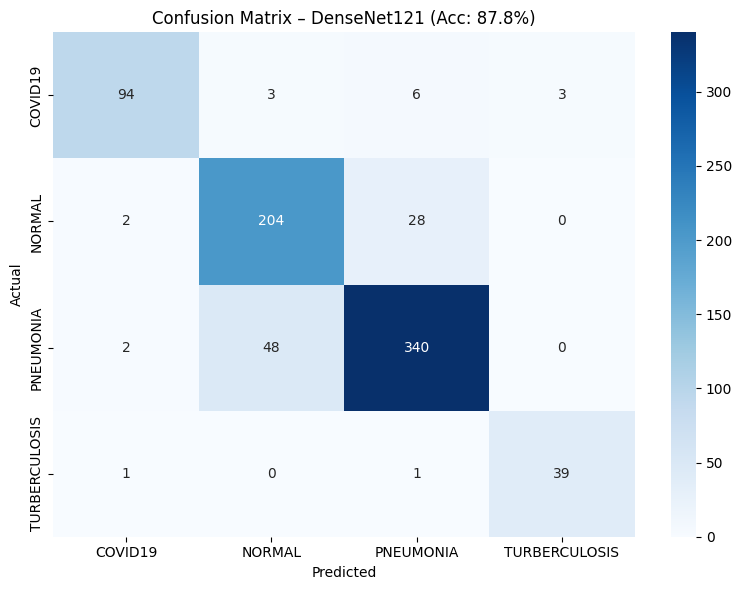

In [18]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix – DenseNet121 (Acc: {accuracy*100:.1f}%)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/DenseNet121_confusion_matrix.png", dpi=150)
plt.show()

## 11. Training Curves

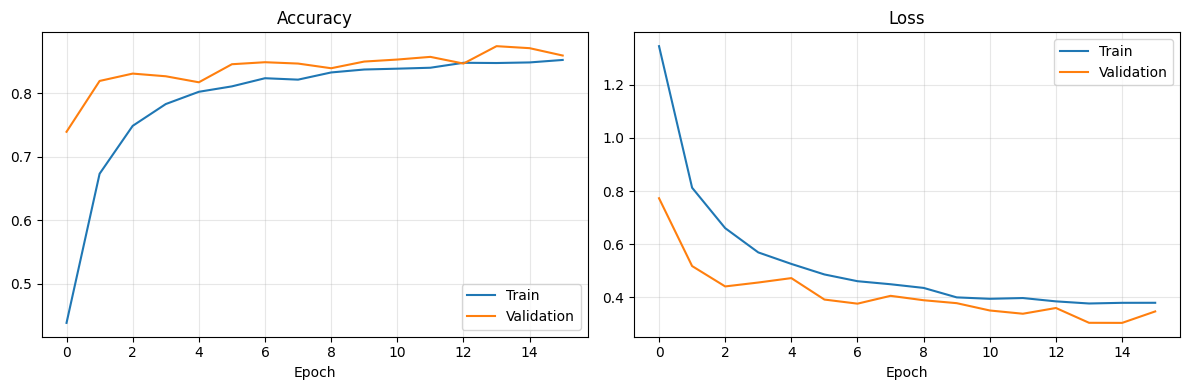

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/DenseNet121_training_curves.png", dpi=150)
plt.show()

## 12. Save Final Model

In [20]:
model.save("/content/drive/MyDrive/DenseNet121_MultiDisease_final.h5")
print("Model saved to Google Drive.")
print(f"Final Test Accuracy: {accuracy*100:.2f}%")

Model saved to Google Drive.
Final Test Accuracy: 87.81%


## End of Notebook

### Summary of Artifacts
- Best checkpoint: `DenseNet121_MultiDisease_best.h5`
- Final model: `DenseNet121_MultiDisease_final.h5`
- Confusion matrix & training curves saved to Drive

These results can be used directly in the research paper and Streamlit application.